In [ ]:

# Install required libraries for Movie Genre Classification

!pip install pandas numpy scikit-learn matplotlib seaborn nltk joblib


In [ ]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

print("All libraries imported successfully!")





All libraries imported successfully!


In [ ]:

from google.colab import files

# Upload the training dataset
uploaded = files.upload()


Saving train_data.txt to train_data (1).txt


In [ ]:

import pandas as pd
import io

filename = list(uploaded.keys())[0]

df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    sep=r"\s*:::\s*",
    engine="python",
    names=["id", "title", "genre", "plot"],
    header=None
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (54214, 4)


,id,title,genre,plot
0,1,Oscar et la dame rose (2009),drama,Listening in to a conversation between his doc...
1,2,Cupid (1997),thriller,A brother and sister with a past incestuous re...
2,3,"Young, Wild and Wonderful (1980)",adult,As the bus empties the students for their fiel...
3,4,The Secret Sin (1915),drama,To help their unemployed father make ends meet...
4,5,The Unrecovered (2007),drama,The film's title refers not only to the un-rec...


In [ ]:

df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of genres:")
print(df["genre"].nunique())

print("\nGenre distribution:")
print(df["genre"].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54214 entries, 0 to 54213
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      54214 non-null  int64 
 1   title   54214 non-null  object
 2   genre   54214 non-null  object
 3   plot    54214 non-null  object
dtypes: int64(1), object(3)
memory usage: 1.7+ MB

Missing values:
id       0
title    0
genre    0
plot     0
dtype: int64

Number of genres:
27

Genre distribution:
genre
drama          13613
documentary    13096
comedy          7447
short           5073
horror          2204
thriller        1591
action          1315
western         1032
reality-tv       884
family           784
adventure        775
music            731
romance          672
sci-fi           647
adult            590
crime            505
animation        498
sport            432
talk-show        391
fantasy          323
mystery          319
musical          277
biography        265
history          243

In [ ]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [ ]:

import re

def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


In [ ]:

df["clean_plot"] = df["plot"].apply(clean_text)

print("Text preprocessing completed!")

display(df[["plot", "clean_plot", "genre"]].head())


Text preprocessing completed!


,plot,clean_plot,genre
0,Listening in to a conversation between his doc...,listening in to a conversation between his doc...,drama
1,A brother and sister with a past incestuous re...,a brother and sister with a past incestuous re...,thriller
2,As the bus empties the students for their fiel...,as the bus empties the students for their fiel...,adult
3,To help their unemployed father make ends meet...,to help their unemployed father make ends meet...,drama
4,The film's title refers not only to the un-rec...,the film s title refers not only to the un rec...,drama


In [ ]:

print("Empty cleaned plots:",
      (df["clean_plot"].str.len() == 0).sum())

print("\nOriginal plot:")
print(df["plot"].iloc[0])

print("\nCleaned plot:")
print(df["clean_plot"].iloc[0])


Empty cleaned plots: 0

Original plot:
Listening in to a conversation between his doctor and parents, 10-year-old Oscar learns what nobody has the courage to tell him. He only has a few weeks to live. Furious, he refuses to speak to anyone except straight-talking Rose, the lady in pink he meets on the hospital stairs. As Christmas approaches, Rose uses her fantastical experiences as a professional wrestler, her imagination, wit and charm to allow Oscar to live life and love to the full, in the company of his friends Pop Corn, Einstein, Bacon and childhood sweetheart Peggy Blue.

Cleaned plot:
listening in to a conversation between his doctor and parents year old oscar learns what nobody has the courage to tell him he only has a few weeks to live furious he refuses to speak to anyone except straight talking rose the lady in pink he meets on the hospital stairs as christmas approaches rose uses her fantastical experiences as a professional wrestler her imagination wit and charm to allow 

In [ ]:

X = df["clean_plot"]
y = df["genre"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)


Input shape: (54214,)
Target shape: (54214,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 43371
Testing records: 10843


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2)
)

# Learn vocabulary and convert training text
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert testing text using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training shape: (43371, 50000)
Testing shape: (10843, 50000)


In [ ]:
print("Total vocabulary size:", len(tfidf.vocabulary_))

print("\nFirst 20 words/features:")
print(list(tfidf.vocabulary_.keys())[:20])

Total vocabulary size: 50000

First 20 words/features:
['scott', 'jacoby', 'boy', 'unhealthy', 'pathological', 'attachment', 'divorced', 'mother', 'increasingly', 'jealous', 'new', 'man', 'life', 'robert', 'klein', 'remarries', 'rage', 'misery', 'overwhelm', 'plots']


In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

print("All machine learning models imported successfully!")

All machine learning models imported successfully!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Predict movie genres
nb_predictions = nb_model.predict(X_test_tfidf)

# Calculate accuracy
nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Multinomial Naive Bayes Results")
print("Accuracy:", round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions, zero_division=0))

Multinomial Naive Bayes Results
Accuracy: 46.83 %

Classification Report:
              precision    recall  f1-score   support

      action       0.00      0.00      0.00       263
       adult       1.00      0.01      0.02       118
   adventure       0.00      0.00      0.00       155
   animation       0.00      0.00      0.00       100
   biography       0.00      0.00      0.00        53
      comedy       0.62      0.18      0.28      1490
       crime       0.00      0.00      0.00       101
 documentary       0.53      0.92      0.67      2619
       drama       0.41      0.87      0.55      2723
      family       0.00      0.00      0.00       157
     fantasy       0.00      0.00      0.00        65
   game-show       0.00      0.00      0.00        39
     history       0.00      0.00      0.00        49
      horror       1.00      0.02      0.04       441
       music       1.00      0.01      0.03       146
     musical       0.00      0.00      0.00        55
     my

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(
    max_iter=500,
    C=2
)

print("Training Logistic Regression...")

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("\nLogistic Regression Results")
print("Accuracy:", round(lr_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    zero_division=0
))

Training Logistic Regression...

Logistic Regression Results
Accuracy: 58.92 %

Classification Report:
              precision    recall  f1-score   support

      action       0.54      0.30      0.39       263
       adult       0.73      0.31      0.43       118
   adventure       0.50      0.13      0.21       155
   animation       0.47      0.07      0.12       100
   biography       0.00      0.00      0.00        53
      comedy       0.52      0.60      0.56      1490
       crime       0.36      0.04      0.07       101
 documentary       0.67      0.86      0.75      2619
       drama       0.55      0.78      0.64      2723
      family       0.49      0.11      0.18       157
     fantasy       0.00      0.00      0.00        65
   game-show       1.00      0.46      0.63        39
     history       0.00      0.00      0.00        49
      horror       0.69      0.59      0.63       441
       music       0.70      0.41      0.52       146
     musical       0.33      0.0

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = LinearSVC(C=1.0, random_state=42)

print("Training Linear SVM...")

svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

svm_accuracy = accuracy_score(y_test, svm_predictions)

print("\nLinear SVM Results")
print("Accuracy:", round(svm_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_predictions,
    zero_division=0
))

Training Linear SVM...

Linear SVM Results
Accuracy: 57.83 %

Classification Report:
              precision    recall  f1-score   support

      action       0.45      0.35      0.39       263
       adult       0.67      0.42      0.51       118
   adventure       0.45      0.23      0.30       155
   animation       0.44      0.17      0.24       100
   biography       0.00      0.00      0.00        53
      comedy       0.53      0.59      0.56      1490
       crime       0.30      0.07      0.11       101
 documentary       0.69      0.82      0.75      2619
       drama       0.56      0.70      0.62      2723
      family       0.41      0.15      0.22       157
     fantasy       0.18      0.03      0.05        65
   game-show       0.88      0.59      0.71        39
     history       0.40      0.04      0.07        49
      horror       0.62      0.64      0.63       441
       music       0.62      0.51      0.56       146
     musical       0.44      0.07      0.12       

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

results = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression",
        "Linear SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, svm_predictions)
    ],
    "Macro F1 Score": [
        f1_score(y_test, nb_predictions, average="macro"),
        f1_score(y_test, lr_predictions, average="macro"),
        f1_score(y_test, svm_predictions, average="macro")
    ],
    "Weighted F1 Score": [
        f1_score(y_test, nb_predictions, average="weighted"),
        f1_score(y_test, lr_predictions, average="weighted"),
        f1_score(y_test, svm_predictions, average="weighted")
    ]
})

display(results.round(4))

,Model,Accuracy,Macro F1 Score,Weighted F1 Score
0,Multinomial Naive Bayes,0.4683,0.0643,0.3461
1,Logistic Regression,0.5892,0.2974,0.5496
2,Linear SVM,0.5783,0.3458,0.5523


In [ ]:
best_model = svm_model

print("Selected Model: Linear SVM")
print("Accuracy:", round(svm_accuracy * 100, 2), "%")

Selected Model: Linear SVM
Accuracy: 57.83 %


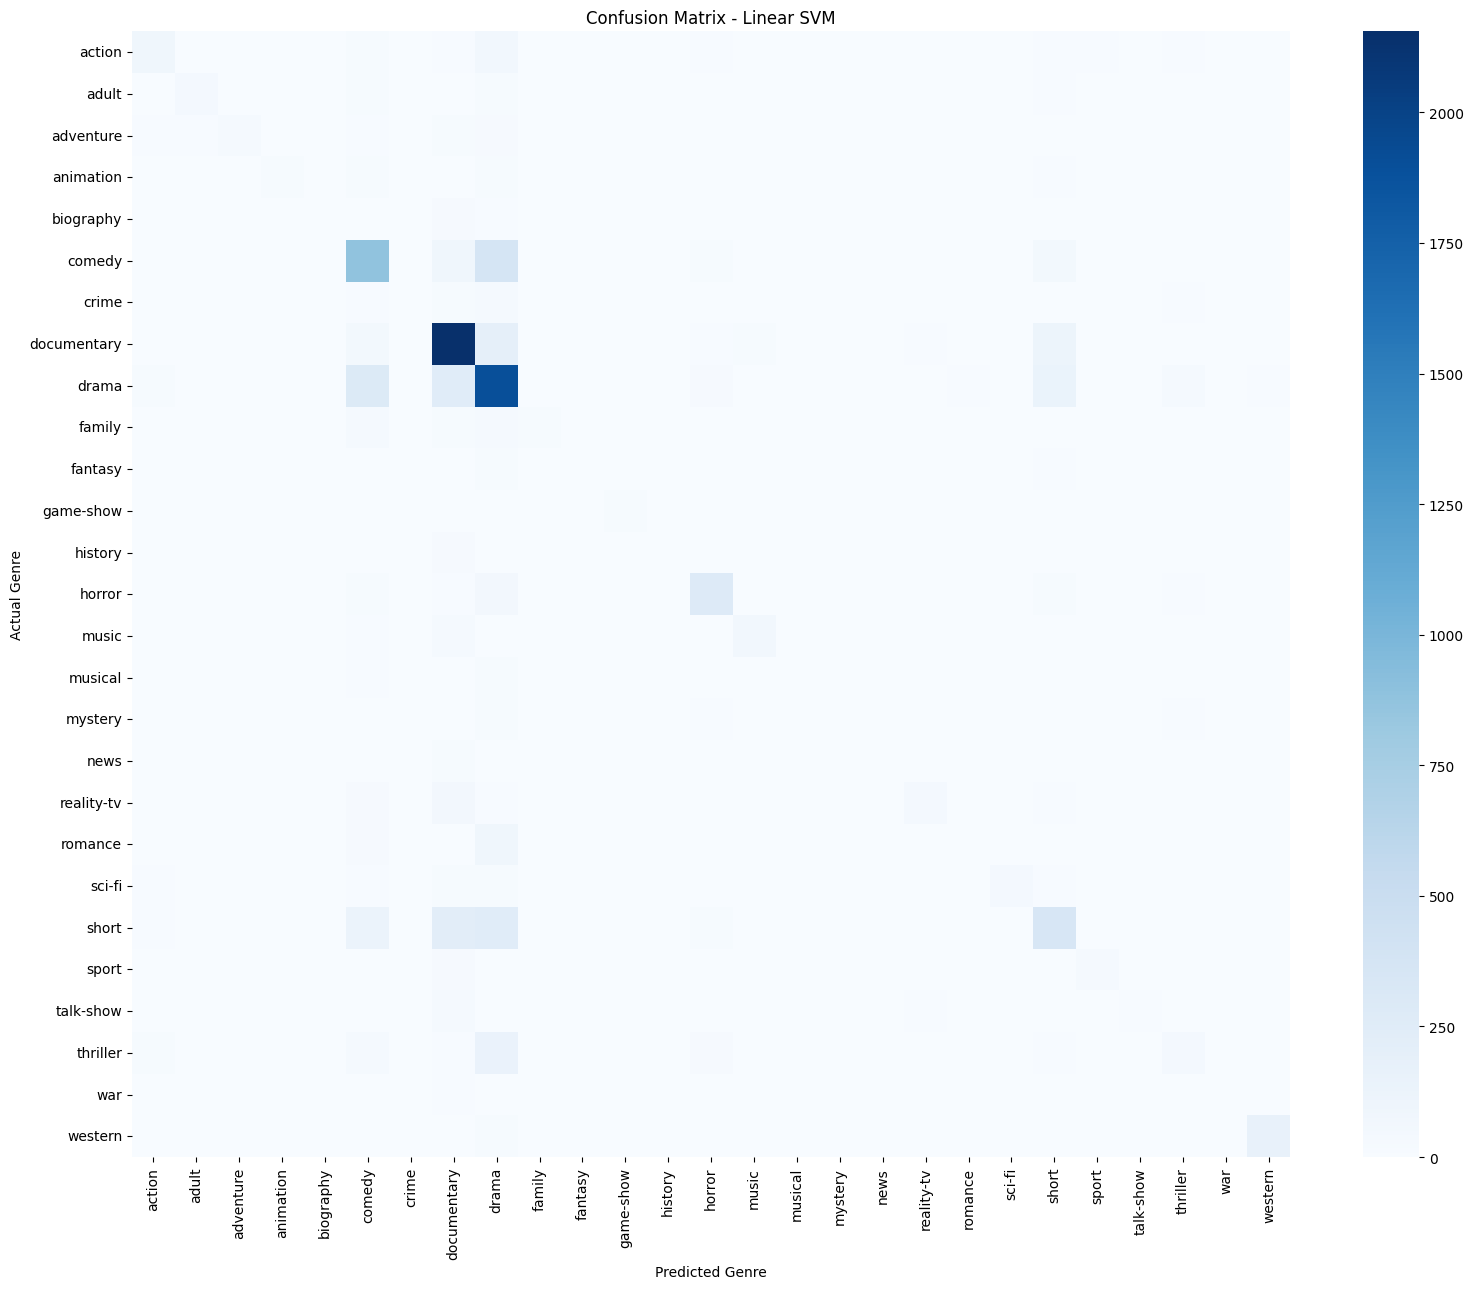

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, svm_predictions, labels=svm_model.classes_)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

In [ ]:
def predict_genre(plot):
    cleaned_plot = clean_text(plot)
    plot_tfidf = tfidf.transform([cleaned_plot])
    prediction = best_model.predict(plot_tfidf)

    return prediction[0]


sample_plot = """
A young scientist discovers a mysterious creature living
in an abandoned laboratory. She must protect the creature
from dangerous experiments.
"""

predicted_genre = predict_genre(sample_plot)

print("Movie Plot:", sample_plot)
print("Predicted Genre:", predicted_genre)

Movie Plot: 
A young scientist discovers a mysterious creature living
in an abandoned laboratory. She must protect the creature
from dangerous experiments.

Predicted Genre: sci-fi


In [ ]:
import joblib

model_data = {
    "tfidf": tfidf,
    "model": best_model
}

joblib.dump(model_data, "movie_genre_classifier.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("movie_genre_classifier.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>